MODEL 1
Risk_Level ~ AVG_NOISE_LVL + Duration_hours
                            OLS Regression Results                            
Dep. Variable:             Risk_Level   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                 1.503e+04
Date:                Sat, 01 Aug 2026   Prob (F-statistic):               0.00
Time:                        15:27:37   Log-Likelihood:                -728.86
No. Observations:                3874   AIC:                             1464.
Df Residuals:                    3871   BIC:                             1483.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

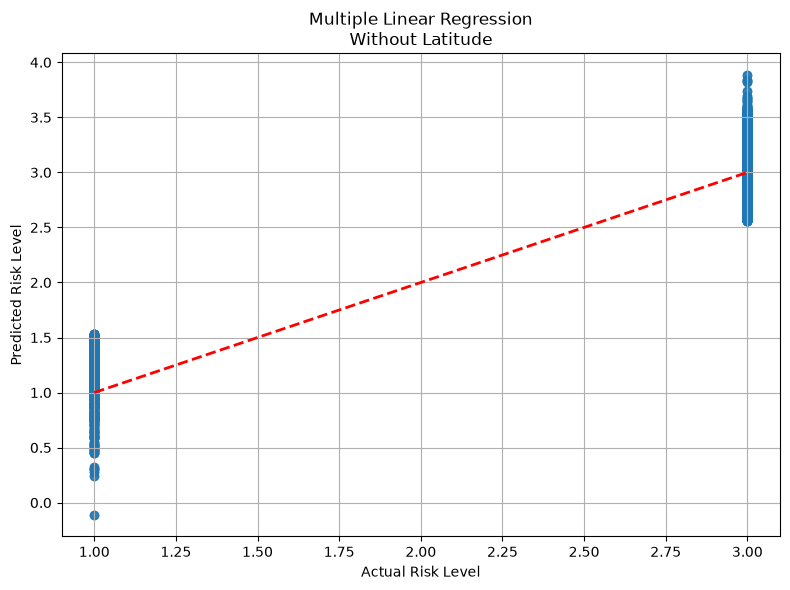

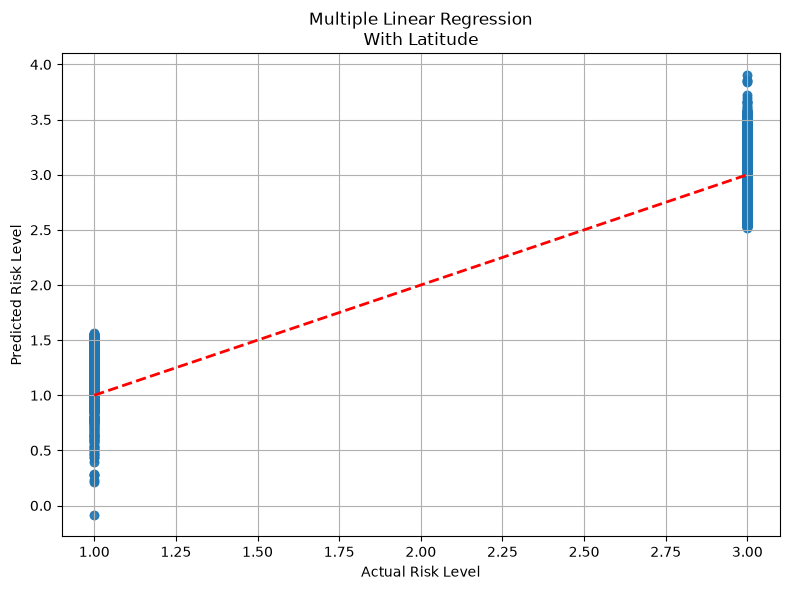


Models completed successfully.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================================
# Load Dataset
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Convert Risk Level
# ==========================================================

df["Risk_Level"] = (
    df["Risk_Level"]
      .astype(str)
      .str.strip()
      .str.lower()
)

risk_mapping = {
    "low":1,
    "medium":2,
    "high":3
}

df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# Convert numeric columns
# ==========================================================

numeric_cols = [
    "AVG_NOISE_LVL",
    "Duration_hours",
    "LATITUDE",
    "Risk_Level"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=numeric_cols)

# ==========================================================
# MODEL 1
# Risk_Level ~ AVG_NOISE_LVL + Duration_hours
# ==========================================================

X1 = df[["AVG_NOISE_LVL", "Duration_hours"]]
Y = df["Risk_Level"]

X1 = sm.add_constant(X1)

model1 = sm.OLS(Y, X1).fit()

print("="*70)
print("MODEL 1")
print("Risk_Level ~ AVG_NOISE_LVL + Duration_hours")
print("="*70)

print(model1.summary())

pred1 = model1.predict(X1)

print("\nR² :", r2_score(Y, pred1))
print("RMSE :", np.sqrt(mean_squared_error(Y, pred1)))

# ==========================================================
# MODEL 2
# Risk_Level ~ AVG_NOISE_LVL + Duration_hours + LATITUDE
# ==========================================================

X2 = df[
    [
        "AVG_NOISE_LVL",
        "Duration_hours",
        "LATITUDE"
    ]
]

X2 = sm.add_constant(X2)

model2 = sm.OLS(Y, X2).fit()

print("="*70)
print("MODEL 2")
print("Risk_Level ~ AVG_NOISE_LVL + Duration_hours + LATITUDE")
print("="*70)

print(model2.summary())

pred2 = model2.predict(X2)

print("\nR² :", r2_score(Y, pred2))
print("RMSE :", np.sqrt(mean_squared_error(Y, pred2)))

# ==========================================================
# Plot Model 1
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    Y,
    pred1,
    alpha=0.7
)

plt.plot(
    [Y.min(), Y.max()],
    [Y.min(), Y.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Risk Level")

plt.ylabel("Predicted Risk Level")

plt.title("Multiple Linear Regression\nWithout Latitude")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Regression_Without_Latitude.png",
    dpi=300
)

plt.show()

# ==========================================================
# Plot Model 2
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    Y,
    pred2,
    alpha=0.7
)

plt.plot(
    [Y.min(), Y.max()],
    [Y.min(), Y.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Risk Level")

plt.ylabel("Predicted Risk Level")

plt.title("Multiple Linear Regression\nWith Latitude")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "Regression_With_Latitude.png",
    dpi=300
)

plt.show()

print("\nModels completed successfully.")

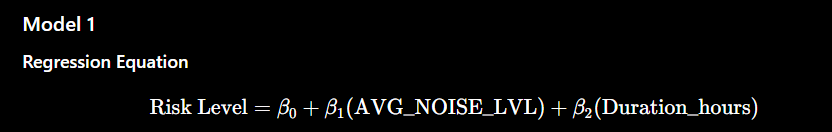

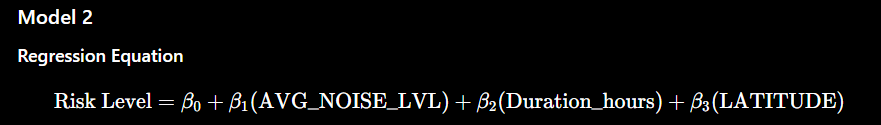